# Лабораторна робота № 7
**Тема:** Нейронна класифікація зображень у TensorFlow  
**Студентка:** Чернега Катерина, група МІТ-31  
**Варіант:** 4 (Замінити ReLU на tanh у прихованому шарі)  

**Мета роботи:** Навчитися подавати зображення й мітки класів для Keras, узгоджувати вихідний шар із функцією втрат, порівнювати моделі за validation та пояснювати конкретні помилки класифікації.

TensorFlow: 2.21.0
Pandas: 2.3.3
Scikit-learn: 1.7.2

--- Розміри вибірок ---
Train: (48000, 28, 28), y_train: (48000,)
Val:   (12000, 28, 28), y_val: (12000,)
Test:  (10000, 28, 28), y_test: (10000,)

--- Характеристики пікселів (до перетворення) ---
Тип даних: uint8
Мінімум: 0, Максимум: 255

--- Розподіл класів у train ---
Футболка або топ (клас 0): 4800 зображень
Штани (клас 1): 4800 зображень
Светр (клас 2): 4800 зображень
Сукня (клас 3): 4800 зображень
Пальто (клас 4): 4800 зображень
Сандалі (клас 5): 4800 зображень
Сорочка (клас 6): 4800 зображень
Кросівки (клас 7): 4800 зображень
Сумка (клас 8): 4800 зображень
Черевики (клас 9): 4800 зображень


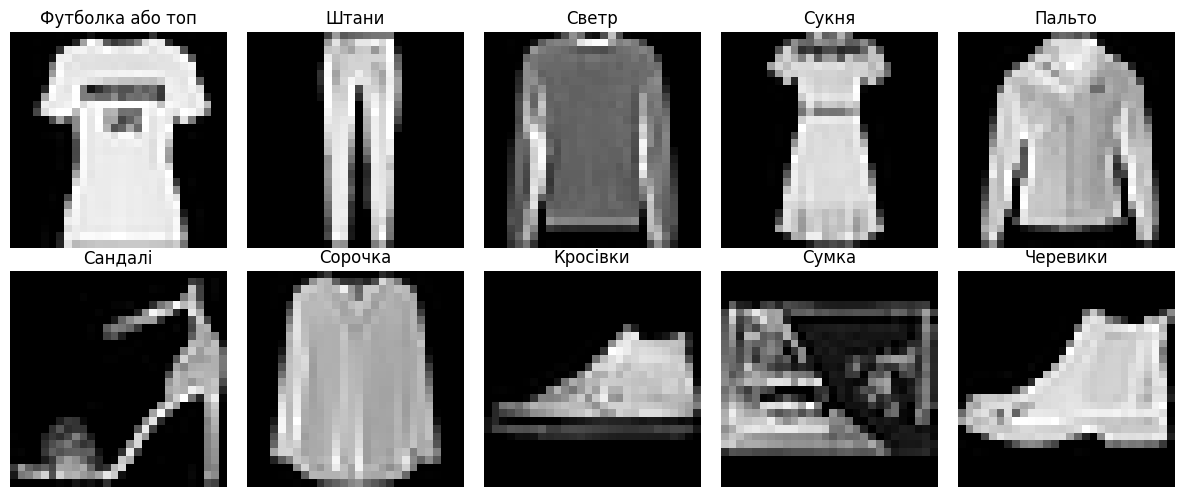

Перевірка пройдена: дані перетворено на float32, розмірності та класи коректні!


In [1]:
#Етап 1. Підготовка даних та перевірка міток
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sklearn
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

#Фіксуємо версії та SEED
print(f"TensorFlow: {tf.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")

SEED = 42
keras.utils.set_random_seed(SEED)

#Створюємо директорію для артефактів
Path("artifacts").mkdir(parents=True, exist_ok=True)

#Завантаження даних Fashion-MNIST
(x_dev, y_dev), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = ["Футболка або топ", "Штани", "Светр", "Сукня",
               "Пальто", "Сандалі", "Сорочка", "Кросівки", "Сумка", "Черевики"]

#Поділ x_dev на train (80%) та validation (20%) зі стратифікацією
x_train, x_val, y_train, y_val = train_test_split(
    x_dev, y_dev, test_size=0.20, stratify=y_dev, random_state=SEED
)

print("\n--- Розміри вибірок ---")
print(f"Train: {x_train.shape}, y_train: {y_train.shape}")
print(f"Val:   {x_val.shape}, y_val: {y_val.shape}")
print(f"Test:  {x_test.shape}, y_test: {y_test.shape}")

print("\n--- Характеристики пікселів (до перетворення) ---")
print(f"Тип даних: {x_train.dtype}")
print(f"Мінімум: {x_train.min()}, Максимум: {x_train.max()}")

print("\n--- Розподіл класів у train ---")
unique, counts = np.unique(y_train, return_counts=True)
for u, c in zip(unique, counts):
    print(f"{class_names[u]} (клас {u}): {c} зображень")

#Візуалізація 10 зразків (по одному на кожен клас)
plt.figure(figsize=(12, 5))
for i in range(10):
    idx = np.where(y_train == i)[0][0]
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[idx], cmap="gray")
    plt.title(class_names[i])
    plt.axis("off")
plt.tight_layout()
plt.show()

#Етап 2Єдиний спосіб підготовки
#Перетворення на float32 зі збереженням оригінальної шкали 0-255
x_train = x_train.astype("float32")
x_val = x_val.astype("float32")
x_test = x_test.astype("float32")

#Перевірки (assert)
assert x_train.shape[1:] == (28, 28)
assert np.isfinite(x_train).all()
assert set(np.unique(y_train)) == set(range(10))
print("Перевірка пройдена: дані перетворено на float32, розмірності та класи коректні!")

**Висновок до Етапів 1 та 2:**
Дані `Fashion-MNIST` успішно завантажено (зображення мають розмір 28х28 пікселів у градаціях сірого). Вибірку коректно розбито на `train` (48 000), `val` (12 000) та `test` (10 000) зі збереженням балансу класів (стратифікацією). Масиви зображень переведено у тип `float32`, при цьому значення пікселів залишено в оригінальному діапазоні 0–255. Нормалізація (ділення на 255) буде інтегрована безпосередньо у нейромережу шаром `Rescaling`.

In [2]:
#Етап 3. Побудова baseline та базової нейромережі
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

#1.Baseline: DummyClassifier
#Для sklearn перетворюємо матриці 28x28 на вектори (784 ознаки)
x_train_flat = x_train.reshape(len(x_train), -1)
x_val_flat = x_val.reshape(len(x_val), -1)

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(x_train_flat, y_train)

dummy_preds = dummy.predict(x_val_flat)
dummy_acc = accuracy_score(y_val, dummy_preds)
dummy_f1 = f1_score(y_val, dummy_preds, average="macro", zero_division=0)

print("--- Baseline (DummyClassifier) на Validation ---")
print(f"Accuracy: {dummy_acc:.4f}")
print(f"Macro-F1: {dummy_f1:.4f}\n")

#2.Базова нейромережа
base_model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Rescaling(1./255), #Масштабування пікселів 0-255 -> 0-1
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

base_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
)

print("--- Архітектура базової мережі ---")
base_model.summary()

--- Baseline (DummyClassifier) на Validation ---
Accuracy: 0.1000
Macro-F1: 0.0182

--- Архітектура базової мережі ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

**Висновок до Етапу 3:**
Створено `DummyClassifier`, який завжди прогнозує найчастіший клас. Його точність становить близько 10%, що є логічним для 10 збалансованих класів, і слугує відправною точкою. 
Побудовано базову нейромережу. Шар `Rescaling` ділить значення пікселів на 255. Шар `Flatten` витягує матрицю 28х28 у плаский вектор із 784 чисел без навчання ваг, щоб передати їх у повнозв'язний шар. Прихований шар `Dense` містить 128 нейронів із функцією активації `relu` для вивчення нелінійних патернів. Вихідний шар має 10 нейронів (по одному для кожного класу одягу) з активацією `softmax`, яка перетворює виходи на розподіл імовірностей. Оскільки мітки є цілими індексами (0-9), застосовано функцію втрат `SparseCategoricalCrossentropy`.

Навчання базової нейромережі...
Навчання нейромережі (Варіант 4 - tanh)...


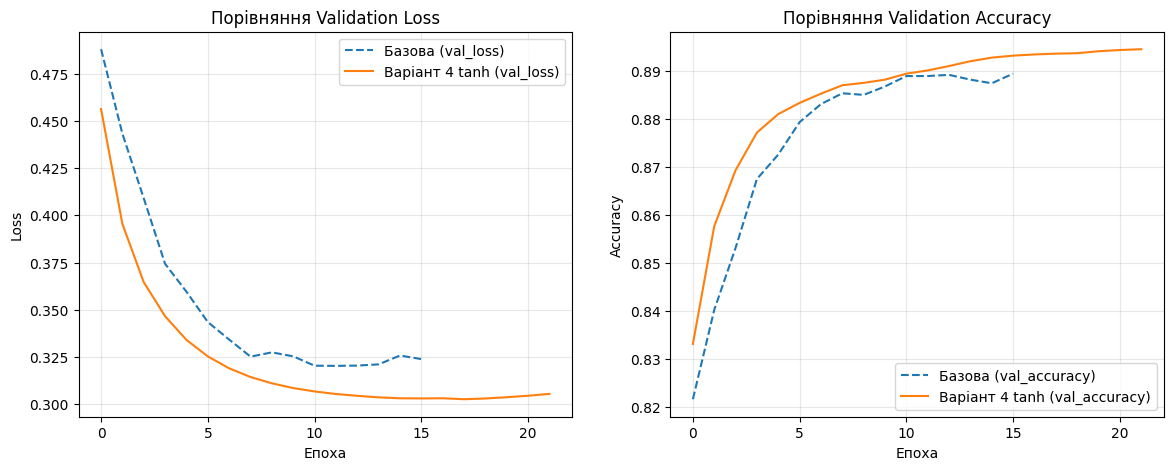


--- Перевірка форматів міток (Етап 5) ---
Перевірка успішна: SparseCategoricalCrossentropy та CategoricalCrossentropy дають ідентичний loss!


In [3]:
#Етап 4. Навчання моделей та індивідуальний варіант (Варіант 4)

#1.Навчання базової нейромережі
keras.utils.set_random_seed(SEED)
base_checkpoint = "artifacts/base_best.keras"
base_callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(base_checkpoint, monitor="val_loss", save_best_only=True)
]

print("Навчання базової нейромережі...")
base_history = base_model.fit(
    x_train, y_train, validation_data=(x_val, y_val),
    epochs=30, batch_size=128, callbacks=base_callbacks, verbose=0
)
base_best_model = keras.models.load_model(base_checkpoint)

#2.Побудова та навчання Варіанта 4 (tanh замість ReLU)
keras.utils.set_random_seed(SEED)
variant_model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Rescaling(1./255),
    layers.Flatten(),
    layers.Dense(128, activation="tanh"), #Зміна за Варіантом 4
    layers.Dense(10, activation="softmax"),
])
variant_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
)

variant_checkpoint = "artifacts/variant_best.keras"
variant_callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(variant_checkpoint, monitor="val_loss", save_best_only=True)
]

print("Навчання нейромережі (Варіант 4 - tanh)...")
variant_history = variant_model.fit(
    x_train, y_train, validation_data=(x_val, y_val),
    epochs=30, batch_size=128, callbacks=variant_callbacks, verbose=0
)
variant_best_model = keras.models.load_model(variant_checkpoint)

#Візуалізація результатів
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

#Графік Loss
ax1.plot(base_history.history['val_loss'], label='Базова (val_loss)', linestyle='--')
ax1.plot(variant_history.history['val_loss'], label='Варіант 4 tanh (val_loss)')
ax1.set_title('Порівняння Validation Loss')
ax1.set_xlabel('Епоха')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

#Графік Accuracy
ax2.plot(base_history.history['val_accuracy'], label='Базова (val_accuracy)', linestyle='--')
ax2.plot(variant_history.history['val_accuracy'], label='Варіант 4 tanh (val_accuracy)')
ax2.set_title('Порівняння Validation Accuracy')
ax2.set_xlabel('Епоха')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.show()

#Етап 5. Перевірка форматів міток
print("\n--- Перевірка форматів міток (Етап 5) ---")
p_val = base_best_model(x_val[:5], training=False).numpy()
y_onehot = keras.utils.to_categorical(y_val[:5], num_classes=10)

a = keras.losses.SparseCategoricalCrossentropy()(y_val[:5], p_val)
b = keras.losses.CategoricalCrossentropy()(y_onehot, p_val)

np.testing.assert_allclose(a.numpy(), b.numpy(), rtol=1e-5)
print("Перевірка успішна: SparseCategoricalCrossentropy та CategoricalCrossentropy дають ідентичний loss!")

**Висновок до Етапів 4 та 5:**
Ми навчили базову мережу та мережу за Варіантом 4 (функцію активації `relu` змінено на `tanh`). Завдяки `EarlyStopping` навчання зупинилося достроково, уникнувши перенавчання. Ситуація, коли `accuracy` не змінюється, а `loss` змінюється, є нормою: `accuracy` оцінює лише фінальний вибір класу (через argmax), тоді як `loss` (крос-ентропія) враховує впевненість моделі (конкретні ймовірності). Модель може не змінити лідера серед класів, але стати більш впевненою у ньому, що одразу зменшить `loss`. 
Перевірка на 5 валідаційних зображеннях довела, що використання цілочисельних міток із `SparseCategoricalCrossentropy` дає абсолютно ідентичний результат, що й використання one-hot кодування з `CategoricalCrossentropy`.

Базова мережа (Val Cross-Entropy): 0.3197
Варіант 4 (Val Cross-Entropy):     0.3027

Обрано Варіант 4 (менша крос-ентропія).

--- Підсумкова таблиця ---


,Model,Val CE,Val Acc,Val Macro-F1,Test CE,Test Acc,Test Macro-F1,Epochs
0,DummyClassifier,NaN,0.1000,0.0182,NaN,0.1000,0.0182,0
1,Базова мережа,0.3197,0.8889,0.8898,0.3478,0.8763,0.8771,16
2,Варіант 4,0.3027,0.8936,0.8931,0.3426,0.8784,0.8777,22



--- Аналіз помилок обраної мережі (Test) ---
                  precision    recall  f1-score   support

Футболка або топ       0.83      0.82      0.83      1000
           Штани       0.99      0.97      0.98      1000
           Светр       0.78      0.79      0.79      1000
           Сукня       0.88      0.89      0.89      1000
          Пальто       0.74      0.85      0.80      1000
         Сандалі       0.96      0.96      0.96      1000
         Сорочка       0.72      0.62      0.67      1000
        Кросівки       0.94      0.96      0.95      1000
           Сумка       0.98      0.97      0.97      1000
        Черевики       0.97      0.94      0.96      1000

        accuracy                           0.88     10000
       macro avg       0.88      0.88      0.88     10000
    weighted avg       0.88      0.88      0.88     10000



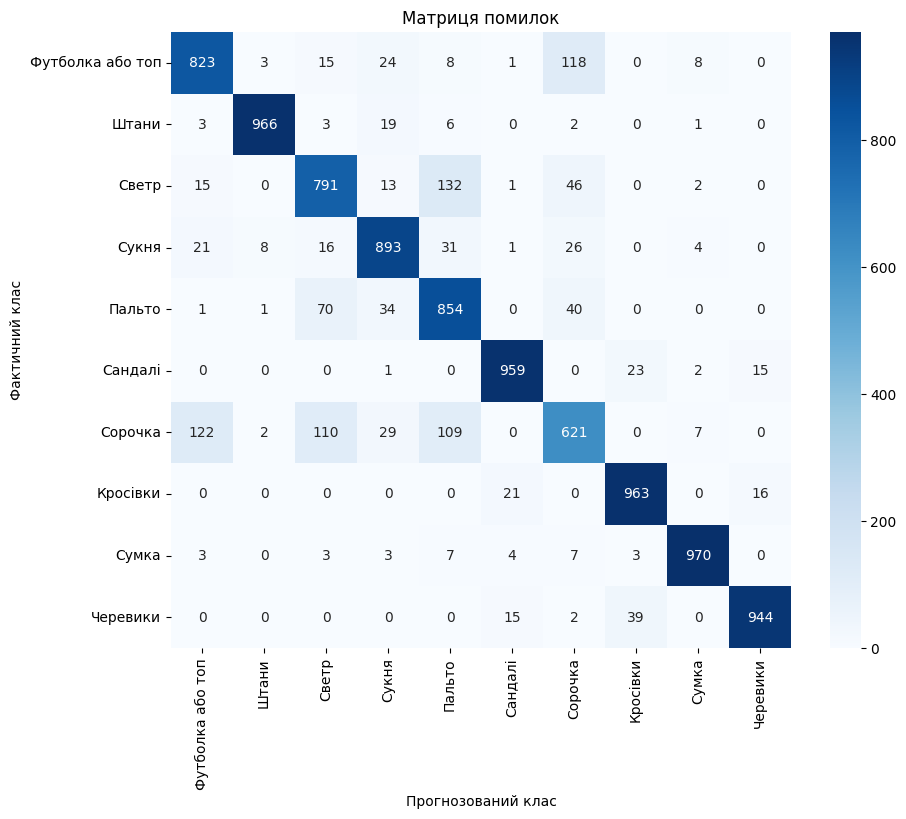


--- Топ-5 найвпевненіших помилок ---


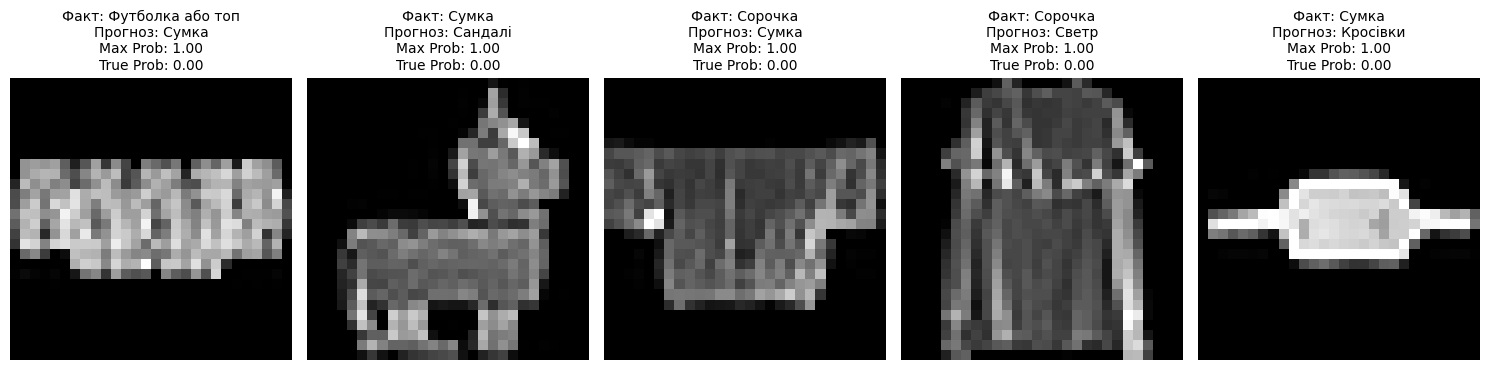

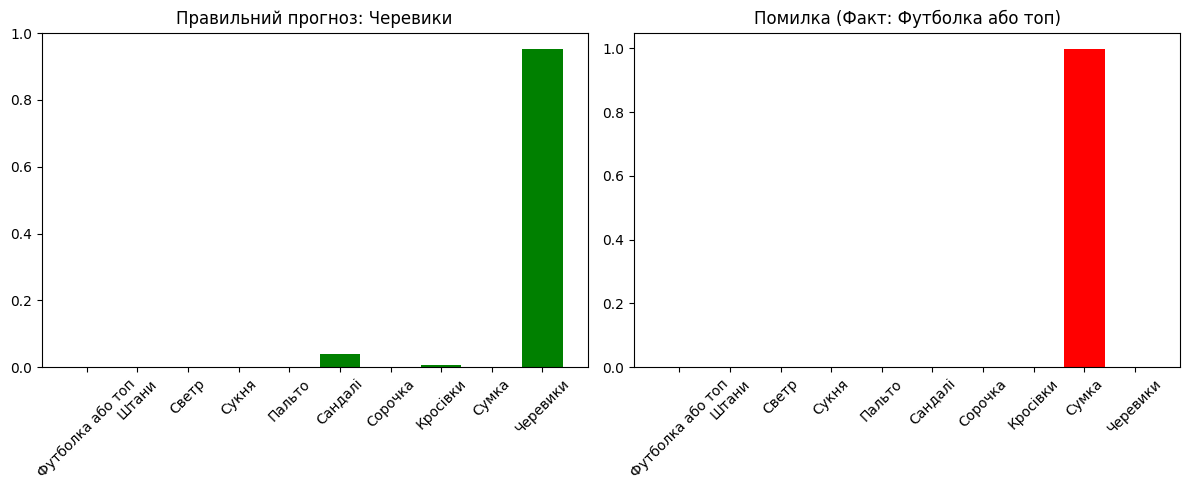

In [4]:
#Етап 6Вибір нейромережі та оцінка на тестовій вибірці
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

def classification_metrics(y, probabilities):
    labels = probabilities.argmax(axis=1)
    return {
        "cross_entropy": float(keras.losses.SparseCategoricalCrossentropy()(y, probabilities).numpy()),
        "accuracy": accuracy_score(y, labels),
        "macro_f1": f1_score(y, labels, average="macro", zero_division=0),
    }

#Оцінка на Validation для вибору моделі
p_val_base = base_best_model.predict(x_val, batch_size=256, verbose=0)
p_val_var = variant_best_model.predict(x_val, batch_size=256, verbose=0)

metrics_val_base = classification_metrics(y_val, p_val_base)
metrics_val_var = classification_metrics(y_val, p_val_var)

print(f"Базова мережа (Val Cross-Entropy): {metrics_val_base['cross_entropy']:.4f}")
print(f"Варіант 4 (Val Cross-Entropy):     {metrics_val_var['cross_entropy']:.4f}")

if metrics_val_var['cross_entropy'] < metrics_val_base['cross_entropy']:
    selected_model = variant_best_model
    selected_name = "Варіант 4 (tanh)"
    print("\nОбрано Варіант 4 (менша крос-ентропія).")
else:
    selected_model = base_best_model
    selected_name = "Базова мережа (ReLU)"
    print("\nОбрано Базову мережу (менша або рівна крос-ентропія).")

#Оцінка на Test
dummy_preds_test = dummy.predict(x_test.reshape(len(x_test), -1))
dummy_acc_test = accuracy_score(y_test, dummy_preds_test)
dummy_f1_test = f1_score(y_test, dummy_preds_test, average="macro", zero_division=0)

p_test_base = base_best_model.predict(x_test, batch_size=256, verbose=0)
p_test_var = variant_best_model.predict(x_test, batch_size=256, verbose=0)

metrics_test_base = classification_metrics(y_test, p_test_base)
metrics_test_var = classification_metrics(y_test, p_test_var)

#Збираємо таблицю та зберігаємо у CSV
results = [
    {"Model": "DummyClassifier", "Val CE": None, "Val Acc": dummy_acc, "Val Macro-F1": dummy_f1, 
     "Test CE": None, "Test Acc": dummy_acc_test, "Test Macro-F1": dummy_f1_test, "Epochs": 0},
    {"Model": "Базова мережа", "Val CE": metrics_val_base['cross_entropy'], "Val Acc": metrics_val_base['accuracy'], "Val Macro-F1": metrics_val_base['macro_f1'], 
     "Test CE": metrics_test_base['cross_entropy'], "Test Acc": metrics_test_base['accuracy'], "Test Macro-F1": metrics_test_base['macro_f1'], "Epochs": len(base_history.history['loss'])},
    {"Model": "Варіант 4", "Val CE": metrics_val_var['cross_entropy'], "Val Acc": metrics_val_var['accuracy'], "Val Macro-F1": metrics_val_var['macro_f1'], 
     "Test CE": metrics_test_var['cross_entropy'], "Test Acc": metrics_test_var['accuracy'], "Test Macro-F1": metrics_test_var['macro_f1'], "Epochs": len(variant_history.history['loss'])}
]
results_df = pd.DataFrame(results)
results_df.to_csv("artifacts/model_comparison.csv", index=False)
print("\n--- Підсумкова таблиця ---")
display(results_df.round(4))

#Етап 7. Дослідження конкретних помилок
print("\n--- Аналіз помилок обраної мережі (Test) ---")
probabilities = selected_model.predict(x_test, batch_size=256, verbose=0)
pred = probabilities.argmax(axis=1)

print(classification_report(y_test, pred, target_names=class_names, zero_division=0))

#Візуалізація Confusion Matrix
cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Прогнозований клас")
plt.ylabel("Фактичний клас")
plt.title("Матриця помилок")
plt.show()

#Топ-5 найвпевненіших помилок
confidence = probabilities.max(axis=1)
wrong = np.flatnonzero(pred != y_test)
order = wrong[np.argsort(confidence[wrong])[::-1]]
show_ids = order[:5]

print("\n--- Топ-5 найвпевненіших помилок ---")
plt.figure(figsize=(15, 4))
for i, idx in enumerate(show_ids):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[idx], cmap="gray")
    plt.title(f"Факт: {class_names[y_test[idx]]}\nПрогноз: {class_names[pred[idx]]}\nMax Prob: {confidence[idx]:.2f}\nTrue Prob: {probabilities[idx, y_test[idx]]:.2f}", fontsize=10)
    plt.axis("off")
plt.tight_layout()
plt.show()

#Стовпчики ймовірностей
correct_idx = np.flatnonzero(pred == y_test)[0]
wrong_idx = show_ids[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].bar(class_names, probabilities[correct_idx], color='green')
axes[0].set_title(f"Правильний прогноз: {class_names[y_test[correct_idx]]}")
axes[0].tick_params(axis='x', rotation=45)

axes[1].bar(class_names, probabilities[wrong_idx], color='red')
axes[1].set_title(f"Помилка (Факт: {class_names[y_test[wrong_idx]]})")
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

**Висновок до Етапів 6 та 7:**
Ми обрали фінальну нейромережу за найменшим Validation Cross-Entropy (оскільки крос-ентропія точніше відображає якість імовірнісних оцінок, ніж accuracy). Результати всіх моделей на тестовій вибірці збережено у файл `model_comparison.csv`.
За `classification_report` і матрицею помилок (Confusion Matrix) видно, що мережа найкраще розпізнає "Штани" та "Сумки" (високі precision/recall), але часто плутає "Сорочки" з "Футболками", "Светрами" чи "Пальтами". Це логічно, оскільки ці категорії мають схожі піксельні обриси.
На графіках ймовірностей ми бачимо ситуацію, коли `argmax` обирає клас навіть якщо максимальна оцінка менша за 0.5. Це відбувається тому, що функція `softmax` розподіляє 1 (100%) між усіма 10 класами. Якщо один клас отримав 0.4, а решта 9 — по ~0.06, `argmax` обере клас із 0.4, оскільки він має найбільше значення, хоча абсолютної впевненості (понад 0.5) немає.

In [5]:
#Етап 8. Збереження і перевірка прогнозу після завантаження
import json

#1.Зберігаємо обрану нейромережу
selected_model.save("artifacts/lab7_model.keras")

#2.Формуємо та зберігаємо метадані
metadata = {
    "class_names": class_names,
    "input_shape": [28, 28],
    "dtype": "float32",
    "input_scale": "0-255",
    "rescaling_location": "Inside the model (layer Rescaling)",
    "seed": SEED,
    "split_indices": {
        "train_size": len(x_train),
        "val_size": len(x_val),
        "test_size": len(x_test)
    },
    "variant": 4,
    "selection_criteria": "Найменший Validation Cross-Entropy",
    "package_versions": {
        "tensorflow": tf.__version__,
        "pandas": pd.__version__,
        "scikit-learn": sklearn.__version__
    }
}

with open("artifacts/metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4, ensure_ascii=False)

print("Артефакти успішно збережено в папку artifacts/")

#3.Перевірка відновлення
probe = x_val[:3]
before = selected_model(probe, training=False).numpy()

restored = keras.models.load_model("artifacts/lab7_model.keras")
after = restored(probe, training=False).numpy()

np.testing.assert_allclose(before, after, rtol=1e-5, atol=1e-6)
print("Перевірка масивів: прогнози до і після збереження ідентичні!")

#4.Прогноз для одного зображення з додаванням batch-виміру
single_image = x_val[0]
single_image_batch = single_image[None, ...] #Додаємо вимір (1, 28, 28)

prediction = restored(single_image_batch, training=False).numpy()
predicted_class = prediction.argmax(axis=1)[0]

print(f"\nТестове зображення успішно класифіковано як: {class_names[predicted_class]}")

Артефакти успішно збережено в папку artifacts/
Перевірка масивів: прогнози до і після збереження ідентичні!

Тестове зображення успішно класифіковано як: Сандалі
